# 04B — Subset Image Model: Image-Level Split

This notebook trains an EfficientNet-B0 image model using only the supplied
`Melanoma-Kaggle-Subset`.

**Split method:** Images are split directly. The same patient may appear in development and validation, so validation performance may be optimistic.

The supplied subset test set remains untouched until final evaluation.

# IMPORTS AND SETTINGS

In [1]:
import os
import random
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score
from sklearn.metrics import average_precision_score
from sklearn.metrics import confusion_matrix
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import efficientnet_b0
from torchvision.models import EfficientNet_B0_Weights
# Plain progress bar: no Jupyter widget download needed
from tqdm import tqdm


PROJECT_FOLDER = r"E:\ADS2002_Melanoma"

SUBSET_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "data",
    "Melanoma-Kaggle-Subset"
)

TRAIN_IMAGE_FOLDER = os.path.join(
    SUBSET_FOLDER,
    "train"
)

TEST_IMAGE_FOLDER = os.path.join(
    SUBSET_FOLDER,
    "test"
)

RESULTS_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "results",
    "subset_image_image_level"
)

MODEL_FOLDER = os.path.join(
    PROJECT_FOLDER,
    "models",
    "subset_image"
)

BEST_MODEL_PATH = os.path.join(
    MODEL_FOLDER,
    "efficientnet_b0_image_level_best.pth"
)

HISTORY_PATH = os.path.join(
    RESULTS_FOLDER,
    "training_history.csv"
)

PREDICTIONS_PATH = os.path.join(
    RESULTS_FOLDER,
    "test_predictions.csv"
)

RANDOM_SEED = 42
IMAGE_SIZE = 224
BATCH_SIZE = 128
NUMBER_OF_EPOCHS = 3

os.makedirs(RESULTS_FOLDER, exist_ok=True)
os.makedirs(MODEL_FOLDER, exist_ok=True)

random.seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)
torch.manual_seed(RANDOM_SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(RANDOM_SEED)

print("Setup complete.")

Setup complete.


# CHECK GPU

In [2]:
print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Using:", device)

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: NVIDIA GeForce RTX 4090
Using: cuda


# LOAD SUBSET LABELS

In [3]:
train_labels = pd.read_csv(
    os.path.join(
        SUBSET_FOLDER,
        "train_labels.csv"
    )
)

test_df = pd.read_csv(
    os.path.join(
        SUBSET_FOLDER,
        "test_labels.csv"
    )
)

print("Available training images:", len(train_labels))
print("Untouched test images:", len(test_df))

print("\nTraining classes:")
print(train_labels["target"].value_counts())

print("\nTest classes:")
print(test_df["target"].value_counts())

Available training images: 6864
Untouched test images: 1988

Training classes:
target
0    6736
1     128
Name: count, dtype: int64

Test classes:
target
0    1957
1      31
Name: count, dtype: int64


# CREATE DEVELOPMENT AND VALIDATION SETS

In [4]:
# Split image rows directly
development_df, validation_df = train_test_split(
    train_labels,
    test_size=0.20,
    random_state=RANDOM_SEED,
    stratify=train_labels["target"]
)

In [5]:
# Make independent copies
development_df = development_df.copy()
validation_df = validation_df.copy()

In [6]:
print("Development images:", len(development_df))
print("Validation images:", len(validation_df))
print("Test images:", len(test_df))

print("\nDevelopment classes:")
print(development_df["target"].value_counts())

print("\nValidation classes:")
print(validation_df["target"].value_counts())

Development images: 5491
Validation images: 1373
Test images: 1988

Development classes:
target
0    5389
1     102
Name: count, dtype: int64

Validation classes:
target
0    1347
1      26
Name: count, dtype: int64


In [7]:
# Check whether patients are shared
development_patient_ids = set(
    development_df["patient_id"]
)

validation_patient_ids = set(
    validation_df["patient_id"]
)

test_patient_ids = set(
    test_df["patient_id"]
)

development_validation_overlap = (
    development_patient_ids.intersection(
        validation_patient_ids
    )
)

development_test_overlap = (
    development_patient_ids.intersection(
        test_patient_ids
    )
)

validation_test_overlap = (
    validation_patient_ids.intersection(
        test_patient_ids
    )
)

print(
    "Patients shared between development and validation:",
    len(development_validation_overlap)
)

print(
    "Patients shared between development and test:",
    len(development_test_overlap)
)

print(
    "Patients shared between validation and test:",
    len(validation_test_overlap)
)

Patients shared between development and validation: 357
Patients shared between development and test: 0
Patients shared between validation and test: 0


# CHECK IMAGE FILES

In [8]:
missing_development_images = 0
missing_validation_images = 0
missing_test_images = 0

for image_name in development_df["image_name"]:

    image_path = os.path.join(
        TRAIN_IMAGE_FOLDER,
        image_name + ".jpg"
    )

    if not os.path.exists(image_path):
        missing_development_images += 1


for image_name in validation_df["image_name"]:

    image_path = os.path.join(
        TRAIN_IMAGE_FOLDER,
        image_name + ".jpg"
    )

    if not os.path.exists(image_path):
        missing_validation_images += 1


for image_name in test_df["image_name"]:

    image_path = os.path.join(
        TEST_IMAGE_FOLDER,
        image_name + ".jpg"
    )

    if not os.path.exists(image_path):
        missing_test_images += 1


print("Missing development images:", missing_development_images)
print("Missing validation images:", missing_validation_images)
print("Missing test images:", missing_test_images)

Missing development images: 0
Missing validation images: 0
Missing test images: 0


# VIEW EXAMPLE IMAGES

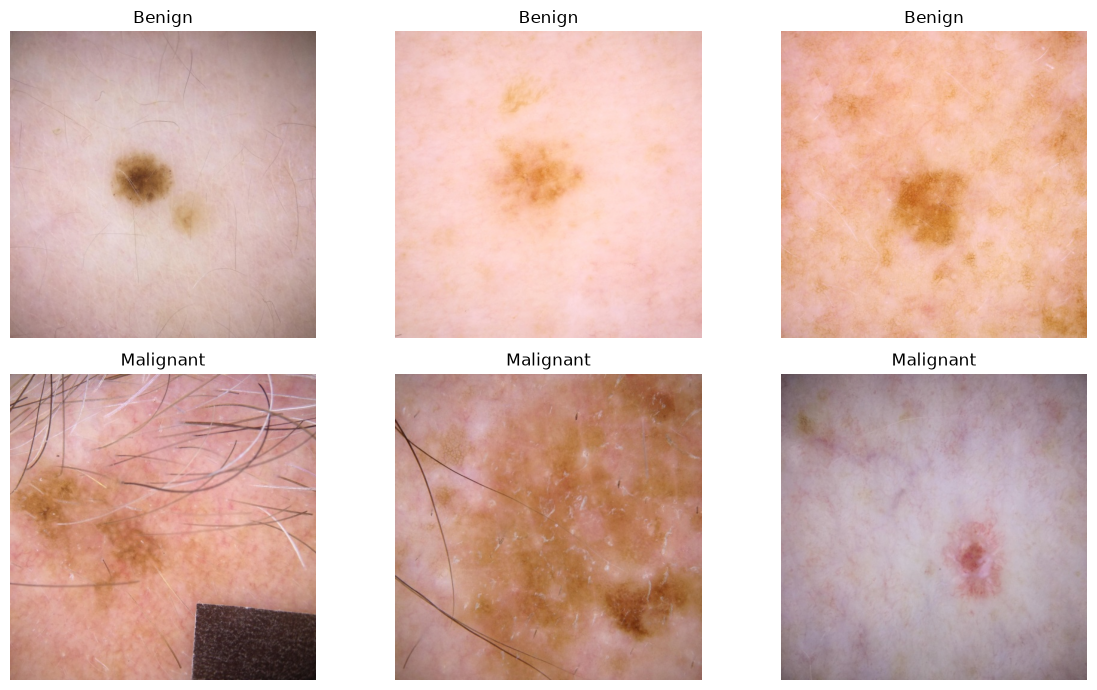

In [9]:
benign_examples = development_df[
    development_df["target"] == 0
].head(3)

malignant_examples = development_df[
    development_df["target"] == 1
].head(3)

example_df = pd.concat([
    benign_examples,
    malignant_examples
])

plt.figure(figsize=(12, 7))

for index in range(len(example_df)):

    row = example_df.iloc[index]

    image_path = os.path.join(
        TRAIN_IMAGE_FOLDER,
        row["image_name"] + ".jpg"
    )

    image = Image.open(image_path)
    image = image.convert("RGB")

    plt.subplot(2, 3, index + 1)
    plt.imshow(image)

    if row["target"] == 1:
        label = "Malignant"
    else:
        label = "Benign"

    plt.title(label)
    plt.axis("off")

plt.tight_layout()

plt.savefig(
    os.path.join(
        RESULTS_FOLDER,
        "example_images.png"
    ),
    dpi=200,
    bbox_inches="tight"
)

plt.show()

# IMAGE TRANSFORMATIONS

In [10]:
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


evaluation_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("Transformations ready.")

Transformations ready.


# PYTORCH DATASET

In [11]:
class MelanomaDataset(Dataset):

    def __init__(
        self,
        dataframe,
        image_folder,
        transform
    ):

        self.dataframe = dataframe.reset_index(
            drop=True
        )

        self.image_folder = image_folder
        self.transform = transform


    def __len__(self):

        return len(self.dataframe)


    def __getitem__(self, index):

        row = self.dataframe.iloc[index]

        image_path = os.path.join(
            self.image_folder,
            row["image_name"] + ".jpg"
        )

        image = Image.open(image_path)
        image = image.convert("RGB")
        image = self.transform(image)

        target = torch.tensor(
            row["target"],
            dtype=torch.float32
        )

        return image, target

# CREATE DATASETS AND DATALOADERS

In [12]:
development_dataset = MelanomaDataset(
    development_df,
    TRAIN_IMAGE_FOLDER,
    train_transform
)

validation_dataset = MelanomaDataset(
    validation_df,
    TRAIN_IMAGE_FOLDER,
    evaluation_transform
)

test_dataset = MelanomaDataset(
    test_df,
    TEST_IMAGE_FOLDER,
    evaluation_transform
)

print("Development dataset:", len(development_dataset))
print("Validation dataset:", len(validation_dataset))
print("Test dataset:", len(test_dataset))

Development dataset: 5491
Validation dataset: 1373
Test dataset: 1988


In [13]:
development_loader = DataLoader(
    development_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

validation_loader = DataLoader(
    validation_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=torch.cuda.is_available()
)

print("Development batches:", len(development_loader))
print("Validation batches:", len(validation_loader))
print("Test batches:", len(test_loader))

Development batches: 43
Validation batches: 11
Test batches: 16


# LOAD EFFICIENTNET-B0

In [14]:
weights = EfficientNet_B0_Weights.DEFAULT

model = efficientnet_b0(
    weights=weights
)

number_of_inputs = model.classifier[1].in_features

model.classifier[1] = nn.Linear(
    number_of_inputs,
    1
)

# Start by training only the final classifier
for parameter in model.features.parameters():
    parameter.requires_grad = False

model = model.to(device)

print(model.classifier)

Sequential(
  (0): Dropout(p=0.2, inplace=True)
  (1): Linear(in_features=1280, out_features=1, bias=True)
)


# HANDLE CLASS IMBALANCE

In [15]:
number_positive = 0
number_negative = 0

for target in development_df["target"]:

    if target == 1:
        number_positive += 1

    else:
        number_negative += 1


positive_weight = (
    number_negative / number_positive
)

print("Malignant images:", number_positive)
print("Benign images:", number_negative)
print("Positive weight:", positive_weight)

Malignant images: 102
Benign images: 5389
Positive weight: 52.833333333333336


In [16]:
positive_weight_tensor = torch.tensor(
    [positive_weight],
    dtype=torch.float32,
    device=device
)

loss_function = nn.BCEWithLogitsLoss(
    pos_weight=positive_weight_tensor
)

optimizer = torch.optim.AdamW(
    model.classifier.parameters(),
    lr=0.001
)

print("Loss function and optimizer ready.")

Loss function and optimizer ready.


# TRAIN FOR THREE EPOCHS

In [17]:
best_validation_roc_auc = 0.0
best_epoch = 0

history = []

overall_start_time = time.time()


for epoch in range(NUMBER_OF_EPOCHS):

    epoch_number = epoch + 1

    print()
    print("Epoch", epoch_number, "of", NUMBER_OF_EPOCHS)
    print("------------------------")

    epoch_start_time = time.time()


    # After epoch 1, train the whole network
    if epoch_number == 2:

        for parameter in model.parameters():
            parameter.requires_grad = True

        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=0.0001
        )

        print("Whole network unfrozen.")


    # TRAINING
    model.train()

    total_training_loss = 0.0


    for images, targets in tqdm(
        development_loader,
        desc="Training"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        targets = targets.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)
        outputs = outputs.squeeze(1)

        loss = loss_function(
            outputs,
            targets
        )

        loss.backward()
        optimizer.step()

        total_training_loss += loss.item()


    average_training_loss = (
        total_training_loss
        / len(development_loader)
    )


    # VALIDATION
    model.eval()

    validation_probabilities = []
    validation_targets = []


    with torch.no_grad():

        for images, targets in tqdm(
            validation_loader,
            desc="Validation"
        ):

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)
            outputs = outputs.squeeze(1)

            probabilities = torch.sigmoid(
                outputs
            )

            probabilities = (
                probabilities.cpu().numpy()
            )

            targets = targets.numpy()

            for probability in probabilities:
                validation_probabilities.append(
                    float(probability)
                )

            for target in targets:
                validation_targets.append(
                    float(target)
                )


    validation_roc_auc = roc_auc_score(
        validation_targets,
        validation_probabilities
    )

    validation_pr_auc = average_precision_score(
        validation_targets,
        validation_probabilities
    )


    epoch_end_time = time.time()

    epoch_minutes = (
        epoch_end_time - epoch_start_time
    ) / 60


    print("Training loss:", average_training_loss)
    print("Validation ROC-AUC:", validation_roc_auc)
    print("Validation PR-AUC:", validation_pr_auc)
    print("Epoch time:", round(epoch_minutes, 2), "minutes")


    history.append([
        epoch_number,
        average_training_loss,
        validation_roc_auc,
        validation_pr_auc,
        epoch_minutes
    ])


    if validation_roc_auc > best_validation_roc_auc:

        best_validation_roc_auc = validation_roc_auc
        best_epoch = epoch_number

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

        print("Best model saved.")


overall_end_time = time.time()

print()
print("Training finished")
print("Best epoch:", best_epoch)
print("Best validation ROC-AUC:", best_validation_roc_auc)
print(
    "Total time:",
    round((overall_end_time - overall_start_time) / 60, 2),
    "minutes"
)


Epoch 1 of 3
------------------------


Validation: 100%|██████████| 11/11 [00:06<00:00,  1.62it/s]


Training loss: 1.3254745671915453
Validation ROC-AUC: 0.7851350579635658
Validation PR-AUC: 0.05194615739246331
Epoch time: 0.81 minutes
Best model saved.

Epoch 2 of 3
------------------------
Whole network unfrozen.


Validation: 100%|██████████| 11/11 [00:06<00:00,  1.61it/s]


Training loss: 1.1193099271419436
Validation ROC-AUC: 0.8883273371023929
Validation PR-AUC: 0.11602821589553494
Epoch time: 2.18 minutes
Best model saved.

Epoch 3 of 3
------------------------


Validation: 100%|██████████| 11/11 [00:05<00:00,  1.84it/s]

Training loss: 0.8873639273089032
Validation ROC-AUC: 0.9080006852835361
Validation PR-AUC: 0.13970404142684167
Epoch time: 1.54 minutes
Best model saved.

Training finished
Best epoch: 3
Best validation ROC-AUC: 0.9080006852835361
Total time: 4.52 minutes


# SAVE AND PLOT TRAINING HISTORY

In [18]:
history_df = pd.DataFrame(
    history,
    columns=[
        "epoch",
        "training_loss",
        "validation_roc_auc",
        "validation_pr_auc",
        "epoch_minutes"
    ]
)

history_df.to_csv(
    HISTORY_PATH,
    index=False
)

display(history_df)

,epoch,training_loss,validation_roc_auc,validation_pr_auc,epoch_minutes
0,1,1.325475,0.785135,0.051946,0.808711
1,2,1.119310,0.888327,0.116028,2.177141
2,3,0.887364,0.908001,0.139704,1.536321


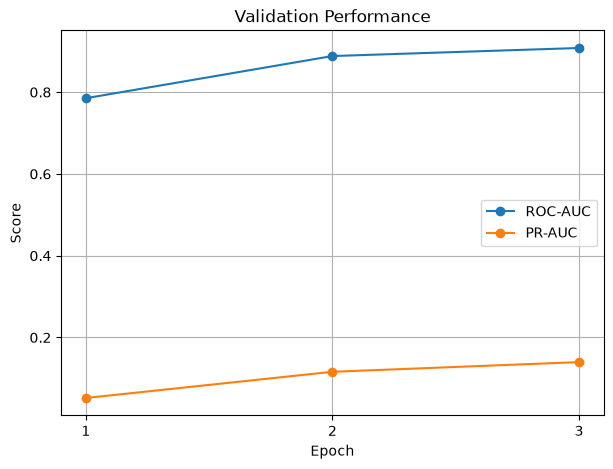

In [19]:
plt.figure(figsize=(7, 5))

plt.plot(
    history_df["epoch"],
    history_df["validation_roc_auc"],
    marker="o",
    label="ROC-AUC"
)

plt.plot(
    history_df["epoch"],
    history_df["validation_pr_auc"],
    marker="o",
    label="PR-AUC"
)

plt.xlabel("Epoch")
plt.ylabel("Score")
plt.title("Validation Performance")
plt.xticks(history_df["epoch"])
plt.legend()
plt.grid()

plt.savefig(
    os.path.join(
        RESULTS_FOLDER,
        "validation_history.png"
    ),
    dpi=300,
    bbox_inches="tight"
)

plt.show()

# FINAL TEST EVALUATION

In [20]:
best_model_weights = torch.load(
    BEST_MODEL_PATH,
    map_location=device,
    weights_only=True
)

model.load_state_dict(
    best_model_weights
)

model.eval()

test_probabilities = []
test_targets = []


with torch.no_grad():

    for images, targets in tqdm(
        test_loader,
        desc="Testing"
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)
        outputs = outputs.squeeze(1)

        probabilities = torch.sigmoid(
            outputs
        )

        probabilities = probabilities.cpu().numpy()
        targets = targets.numpy()

        for probability in probabilities:
            test_probabilities.append(
                float(probability)
            )

        for target in targets:
            test_targets.append(
                float(target)
            )


print("Test predictions complete.")

Testing: 100%|██████████| 16/16 [00:10<00:00,  1.60it/s]

Test predictions complete.


In [21]:
test_roc_auc = roc_auc_score(
    test_targets,
    test_probabilities
)

test_pr_auc = average_precision_score(
    test_targets,
    test_probabilities
)

test_predictions = []

for probability in test_probabilities:

    if probability >= 0.5:
        test_predictions.append(1)

    else:
        test_predictions.append(0)


test_cm = confusion_matrix(
    test_targets,
    test_predictions
)

tn = test_cm[0][0]
fp = test_cm[0][1]
fn = test_cm[1][0]
tp = test_cm[1][1]

sensitivity = tp / (tp + fn)
specificity = tn / (tn + fp)
precision = tp / (tp + fp)

print("Test results")
print("------------")
print("ROC-AUC:", test_roc_auc)
print("PR-AUC:", test_pr_auc)
print("Sensitivity:", round(sensitivity * 100, 2), "%")
print("Specificity:", round(specificity * 100, 2), "%")
print("Precision:", round(precision * 100, 2), "%")

print("\nConfusion matrix:")
print(test_cm)

Test results
------------
ROC-AUC: 0.8746270624886676
PR-AUC: 0.12073428099211195
Sensitivity: 93.55 %
Specificity: 60.81 %
Precision: 3.64 %

Confusion matrix:
[[1190  767]
 [   2   29]]


In [22]:
predictions_df = test_df[
    ["image_name", "patient_id", "target"]
].copy()

predictions_df["image_probability"] = test_probabilities
predictions_df["prediction"] = test_predictions

predictions_df.to_csv(
    PREDICTIONS_PATH,
    index=False
)

summary_df = pd.DataFrame({
    "split_method": ["image_level"],
    "best_epoch": [best_epoch],
    "best_validation_roc_auc": [best_validation_roc_auc],
    "test_roc_auc": [test_roc_auc],
    "test_pr_auc": [test_pr_auc],
    "sensitivity": [sensitivity],
    "specificity": [specificity],
    "precision": [precision],
    "true_negative": [tn],
    "false_positive": [fp],
    "false_negative": [fn],
    "true_positive": [tp]
})

summary_df["split_method"] = "image_level"

summary_df.to_csv(
    os.path.join(
        RESULTS_FOLDER,
        "final_metrics.csv"
    ),
    index=False
)

print("Predictions and metrics saved to:")
print(RESULTS_FOLDER)

Predictions and metrics saved to:
E:\ADS2002_Melanoma\results\subset_image_image_level


# CONCLUSION

This model used the **image-level split**.

The validation result should be interpreted together with the number of patients
shared between development and validation. The untouched test result is the fairest
measure for comparing the two notebooks.